<a href="https://colab.research.google.com/github/SariChiba/El_Turismo_Esta_De_Vuelta/blob/ileana/notebook/turismo_datacenter.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

---

# Análisis de turismo no residente en Argentina

---
###### **Lo primero que vamos a hacer es importar las librerías que vamos a necesitar para poder correr correctamente el notebook.**

---

## _Análisis inicial_

In [33]:
import pandas as pd #para manipular los archivos
import matplotlib.pyplot as plt #para hacer gráficos
import seaborn as sb #para hacer gráficos
import numpy as np #para realizar operaciones matemáticas

In [34]:
#Vamos a cargar el dataset elegido a través de una url
url = 'https://raw.githubusercontent.com/SariChiba/El_Turismo_Esta_De_Vuelta/main/dataset/turistas-no-residentes-serie.csv'

#A continuación, le pedimos a pandas que lo lea y le asignamos un nombre para crear el dataframe
turismo = pd.read_csv(url)

#Ahora vamos a ver el dataframe que acabamos de crear
turismo

,indice_tiempo,medio_de_transporte,pais_origen,viajes_de_turistas_no_residentes,observaciones
0,2010-01-01,Aérea,Bolivia,4390,NaN
1,2010-01-01,Aérea,Brasil,72669,NaN
2,2010-01-01,Aérea,Chile,14726,NaN
3,2010-01-01,Aérea,Paraguay,4062,NaN
4,2010-01-01,Aérea,Uruguay,3512,NaN
...,...,...,...,...,...
5395,2026-08-01,Terrestre,Uruguay,27147,Dato provisorio
5396,2026-08-01,Terrestre,EE.UU. y Canadá,2268,Dato provisorio
5397,2026-08-01,Terrestre,Resto de América,8320,Dato provisorio
5398,2026-08-01,Terrestre,Europa,12908,Dato provisorio


A continuación, decidimos eliminar la columna ```observaciones``` porque consideramos que no aporta datos de importancia en nuestro análisis, ya que nuestra investigación se centra en la evolución temporal, los países de origen y el impacto de la pandemia. Ninguna de estas preguntas requiere saber si un dato es "provisorio" o no.


⚠️ Importante
---
Utilizamos la ayuda de la _**IA**_ y el apoyo de los apuntes de la materia para definir una función que elimine la columna sin romper ni provocar daños en el df.

> _Prompt utilizado: Eliminar la columna 'observaciones' de un DataFrame de pandas de forma permanente (inplace)_

In [35]:
# Definimos una función que recibe un DataFrame y el nombre de la columna a eliminar
def eliminar_columna(df, columna):
    if columna in df.columns:
        df.drop(columns=[columna], inplace=True)
        print(f"Columna '{columna}' eliminada exitosamente.")
    else:
        print(f"La columna '{columna}' no existe en el DataFrame.")

eliminar_columna(turismo, 'observaciones')
turismo.head()

Columna 'observaciones' eliminada exitosamente.


,indice_tiempo,medio_de_transporte,pais_origen,viajes_de_turistas_no_residentes
0,2010-01-01,Aérea,Bolivia,4390
1,2010-01-01,Aérea,Brasil,72669
2,2010-01-01,Aérea,Chile,14726
3,2010-01-01,Aérea,Paraguay,4062
4,2010-01-01,Aérea,Uruguay,3512


Ahora, vamos a realizar otra modificación que consideramos importante, porque estamos trabajando principalmente con períodos de tiempo y es necesario que Pandas reconozca las fechas como tal, así que convertimo ```indice_tiempo``` a datetime.

In [36]:
#Convertimos la columna indice_tiempo a formato datetime para que pandas la reconozca de la forma correcta
turismo['indice_tiempo'] = pd.to_datetime(turismo['indice_tiempo'])

In [37]:
#Mostramos las primeras filas de nuestro dataframe con la ayuda de .head(10)
turismo.head(10)

,indice_tiempo,medio_de_transporte,pais_origen,viajes_de_turistas_no_residentes
0,2010-01-01,Aérea,Bolivia,4390
1,2010-01-01,Aérea,Brasil,72669
2,2010-01-01,Aérea,Chile,14726
3,2010-01-01,Aérea,Paraguay,4062
4,2010-01-01,Aérea,Uruguay,3512
5,2010-01-01,Aérea,EE.UU. y Canadá,42783
6,2010-01-01,Aérea,Resto de América,36410
7,2010-01-01,Aérea,Europa,75995
8,2010-01-01,Aérea,Resto del mundo,15212
9,2010-01-01,Fluvial/Marítima,Bolivia,2304


In [38]:
#Mostramos las últimas filas usando .tail, también seleccionamos 10
turismo.tail(10)

,indice_tiempo,medio_de_transporte,pais_origen,viajes_de_turistas_no_residentes
5390,2026-08-01,Fluvial/Marítima,Resto del mundo,1228
5391,2026-08-01,Terrestre,Bolivia,7336
5392,2026-08-01,Terrestre,Brasil,34488
5393,2026-08-01,Terrestre,Chile,10373
5394,2026-08-01,Terrestre,Paraguay,25351
5395,2026-08-01,Terrestre,Uruguay,27147
5396,2026-08-01,Terrestre,EE.UU. y Canadá,2268
5397,2026-08-01,Terrestre,Resto de América,8320
5398,2026-08-01,Terrestre,Europa,12908
5399,2026-08-01,Terrestre,Resto del mundo,2251


In [39]:
#Inspeccionamos el archivo con la función info
#ACLARACIÓN: unas celdas mas adelante hacemos una inspección más detallada y limpia, pero el .info() nos da un pantallazo inicial bastante más rápido

turismo.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5400 entries, 0 to 5399
Data columns (total 4 columns):
 #   Column                            Non-Null Count  Dtype         
---  ------                            --------------  -----         
 0   indice_tiempo                     5400 non-null   datetime64[ns]
 1   medio_de_transporte               5400 non-null   object        
 2   pais_origen                       5400 non-null   object        
 3   viajes_de_turistas_no_residentes  5400 non-null   int64         
dtypes: datetime64[ns](1), int64(1), object(2)
memory usage: 168.9+ KB


In [40]:
#Pedimos que chequee si hay valores nulos
turismo.isnull().sum()

,0
indice_tiempo,0
medio_de_transporte,0
pais_origen,0
viajes_de_turistas_no_residentes,0


En este caso, nos devulve ```0``` en todas las filas porque no tenemos valores nulos.

In [41]:
#Aplicamos .duplicated para revisar si hay filas duplicadas
turismo.duplicated()

,0
0,False
1,False
2,False
3,False
4,False
...,...
5395,False
5396,False
5397,False
5398,False


Nos parece relevante aclarar que podríamos haber utilizado ```turismo.duplicated().sum()``` para obtener el mismo resultado, pero la diferencia con el que finalmente utilizamos es debido a la forma en que se mostraba el resultado.

```turismo.duplicated().sum()``` nos devuelve ```np.int64(0)```. Nos parece mejor y más llamativa la opción finalmente utilizada, aunque con ambos obtengamos el mismo resultado: **no hay duplicados en este dataframe.**

En la siguiente celda vamos a realizar lo restante del análisis inicial de forma más limpia.

In [42]:
print("Dimensiones:", turismo.shape)
print("Columnas :", list(turismo.columns))
print("\nTipos de dato:")
print(turismo.dtypes)

print("MEMORIA  : %.2f MB" % (turismo.memory_usage(deep=True).sum() / 1024**2))

#Definimos los mínimos y máximos que vamos a usar en el print de abajo
fecha_min = turismo["indice_tiempo"].min()
fecha_max = turismo["indice_tiempo"].max()

print("\nPeríodo que cubre:", fecha_min, "→", fecha_max)

cantidad_visitantes_total = turismo['viajes_de_turistas_no_residentes'].sum()
print("\nCantidad total de visitantes no residentes:", cantidad_visitantes_total)

turismo.describe(exclude="datetime").round(2)

Dimensiones: (5400, 4)
Columnas : ['indice_tiempo', 'medio_de_transporte', 'pais_origen', 'viajes_de_turistas_no_residentes']

Tipos de dato:
indice_tiempo                       datetime64[ns]
medio_de_transporte                         object
pais_origen                                 object
viajes_de_turistas_no_residentes             int64
dtype: object
MEMORIA  : 0.82 MB

Período que cubre: 2010-01-01 00:00:00 → 2026-08-01 00:00:00

Cantidad total de visitantes no residentes: 97999975


,medio_de_transporte,pais_origen,viajes_de_turistas_no_residentes
count,5400,5400,5400.00
unique,3,9,NaN
top,Aérea,Bolivia,NaN
freq,1800,600,NaN
mean,NaN,NaN,18148.14
std,NaN,NaN,21317.76
min,NaN,NaN,0.00
25%,NaN,NaN,3325.00
50%,NaN,NaN,9184.00
75%,NaN,NaN,27894.75


¿Por qué aparecen los NaN?

Las métricas como unique, top y freq solo aplican a texto y no se calculan para números, entonces para la columna de ```viajes_de_turistas_no_residentes``` se muestra NaN.
Las métricas como mean (promedio), std (desviación estándar), min, max y los percentiles solo aplican a números y no se pueden calcular para texto, entonces para ```medios_de_transporte``` y ```pais_origen``` se muestra NaN.

Por otro lado, un dato interesante que podemos obtener de este cuadro es el promedio para los viajes, que nos indica que la cantidad promedio de viajes para cada mes de los 16 años que recorre este dataframe es **18.148**. Un número no tan grande a simple vista, pero puede verse afectado porque tenemos la pandemia de COVID-19 en el medio, donde hay meses sin viajes registrados o muy pocos.

# _Pregunta de investigación_

---

> ## **¿Cómo evolucionó el turismo no residente en Argentina en los últimos 16 años?**

La principal motivación para realizar el análisis de la evolución del turismo en nuestro país es guiada por la pandemia de COVID-19, donde uno de los sectores más afectados, durante el aislamiento, y al que más trabajo le costó recuperarse, cuando todo se fue abriendo nuevamente de manera paulatina, fue al sector de Turismo.

Uno de nuestros objetivos, más allá de realizar el análisis de manera exitosa, es poder plasmar de una manera bastante clara en este notebook: comparaciones de la cantidad de viajes entre los años previos y posteriores a la pandemia, además clasificar comparaciones por países y medios de transporte. Es decir, realizar un análisis gráfico y textual que pueda entenderse sin problemas.


A continuación, empezamos con el análisis gráfico de lo que hasta ahora se planteó con palabras.

In [43]:
# Obtenemos la cantidad de Visitantes no residentes por año

# Crear la columna año utilizando el tipo datetime ya convertido al inicio
turismo['anio'] = turismo['indice_tiempo'].dt.year

# Sumar los viajes de todos los meses, países y transportes de cada año
visitas_por_anio = (
    turismo.groupby('anio')['viajes_de_turistas_no_residentes']
      .sum()
      .reset_index()
)

# Renombrar las columnas para la presentación
visitas_por_anio.columns = ['Año', 'Cantidad de visitas']

# Creamos una copia formateada visualmente con puntos como separadores de miles
visitas_por_anio_formateado = visitas_por_anio.copy()
visitas_por_anio_formateado['Cantidad de visitas'] = visitas_por_anio_formateado['Cantidad de visitas'].map(lambda x: f"{x:,.0f}".replace(",", "."))

# Mostrar los resultados con el formato de lectura mejorado
display(visitas_por_anio_formateado)

,Año,Cantidad de visitas
0,2010,6.738.593
1,2011,6.674.029
2,2012,6.461.769
3,2013,6.510.286
4,2014,7.165.219
5,2015,6.815.623
6,2016,6.668.207
7,2017,6.711.248
8,2018,6.941.767
9,2019,7.398.973


In [44]:
# Obtenemos el año con mayor cantidad de visitantes de acuerdo a nuestra muestra:

anio_max_visitas = visitas_por_anio.loc[visitas_por_anio['Cantidad de visitas'].idxmax()]

print(f"El año con mayor cantidad de visitantes fue {int(anio_max_visitas['Año'])} con {int(anio_max_visitas['Cantidad de visitas']):,} visitas.")

El año con mayor cantidad de visitantes fue 2019 con 7,398,973 visitas.


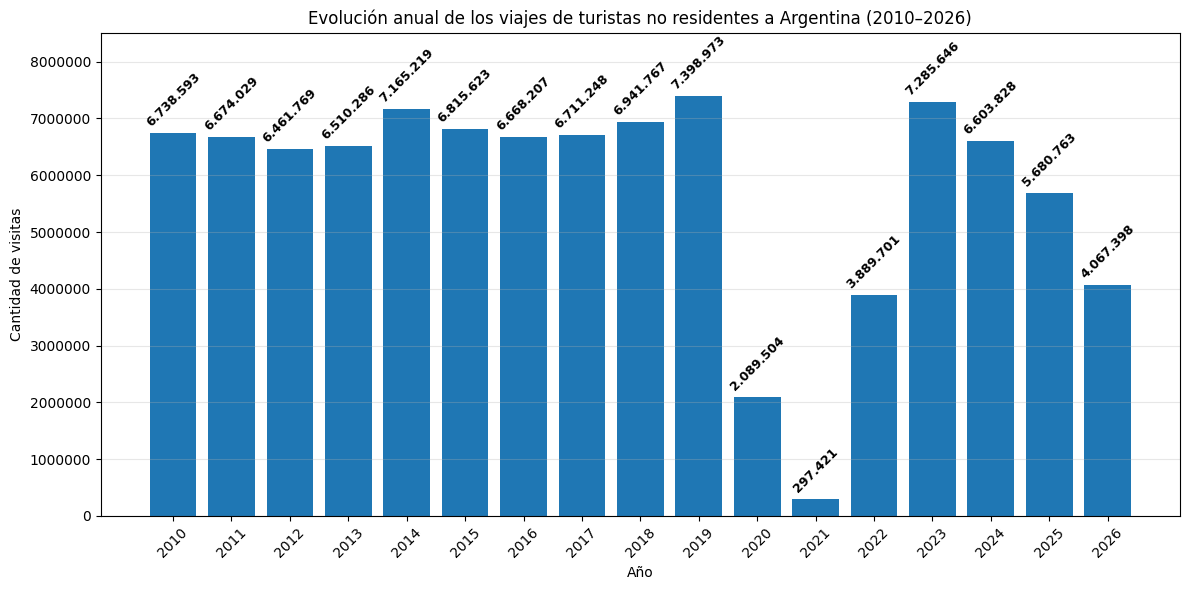

In [45]:
# GRÁFICAMENTE CON ETIQUETAS DE VALORES EN NEGRITA Y FORMATEADAS CON PUNTOS:

fig, ax = plt.subplots(figsize=(12, 6))
bars = ax.bar(
    visitas_por_anio['Año'],
    visitas_por_anio['Cantidad de visitas'],
    width=0.8
)

# Crear las etiquetas formateadas con punto como separador de miles
etiquetas_formateadas = [f"{int(valor):,}".replace(",", ".") for valor in visitas_por_anio['Cantidad de visitas']]

# Añadir los valores numéricos sobre cada columna con estilo negrita (weight='bold')
ax.bar_label(bars, labels=etiquetas_formateadas, padding=3, rotation=45, fontsize=9, weight='bold')

plt.title('Evolución anual de los viajes de turistas no residentes a Argentina (2010–2026)')
plt.xlabel('Año')
plt.ylabel('Cantidad de visitas')
plt.xticks(visitas_por_anio['Año'], rotation=45)

# Ajustamos el límite de y para que las etiquetas no se corten
plt.ylim(0, visitas_por_anio['Cantidad de visitas'].max() * 1.15)

plt.ticklabel_format(axis="y", style="plain")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### ¿Cómo interpretar los resultados?

El gráfico muestra la evolución de la cantidad de viajes de turistas no residentes a Argentina entre 2010 y 2026.

Durante el período 2010-2019, se observa un comportamiento relativamente estable, con fluctuaciones moderadas y un máximo de aproximadamente 7,4 millones de viajes en 2019.

En 2020 y 2021 se registra una disminución significativa, coincidente con la pandemia de COVID-19 y las restricciones a los viajes internacionales.

A partir de 2022 se evidencia una recuperación del turismo, alcanzando en 2023 valores cercanos a los registrados antes de la pandemia. Sin embargo, durante 2024 y 2025 se observa una nueva tendencia descendente.

Es importante señalar que los datos correspondientes a 2026 abarcan únicamente hasta agosto, por lo que no pueden compararse directamente con los años completos.

En conclusión, el turismo no residente en Argentina presentó un comportamiento relativamente estable antes de la pandemia, seguido de una fuerte caída, una posterior recuperación y una nueva disminución en los últimos años analizados.

<br>

---
#### **¿Qué países o regiones aportaron más turistas durante el periodo analizado?**


Calculamos la cantidad de viajes por país o región.<br>
Primero agrupamos los datos por pais_origen y sumamos la cantidad de viajes registrados.

In [46]:
# Calcular los viajes por país/región si no se definió previamente
visitas_por_pais = turismo.groupby('pais_origen')['viajes_de_turistas_no_residentes'].sum().sort_values(ascending=False)

# Calcular el porcentaje de visitas de cada país/región respecto al total general
visitas_total_general = visitas_por_pais.sum()
porcentaje_por_pais = (visitas_por_pais / visitas_total_general) * 100

# Crear un DataFrame para mostrar los resultados con formato
# Formateamos la cantidad de visitas con puntos como separador de miles y el porcentaje con '%'
tabla_porcentajes = pd.DataFrame({
    'Cantidad de visitas': visitas_por_pais.map(lambda x: f"{x:,.0f}".replace(",", ".")),
    'Porcentaje (%)': porcentaje_por_pais.round(2).map('{:.2f}%'.format)
})

display(tabla_porcentajes)

,Cantidad de visitas,Porcentaje (%)
pais_origen,,
Brasil,19.206.027,19.60%
Chile,15.868.607,16.19%
Europa,13.424.077,13.70%
Uruguay,12.917.528,13.18%
Paraguay,10.885.956,11.11%
Resto de América,9.241.591,9.43%
EE.UU. y Canadá,7.144.982,7.29%
Bolivia,5.517.186,5.63%
Resto del mundo,3.794.021,3.87%


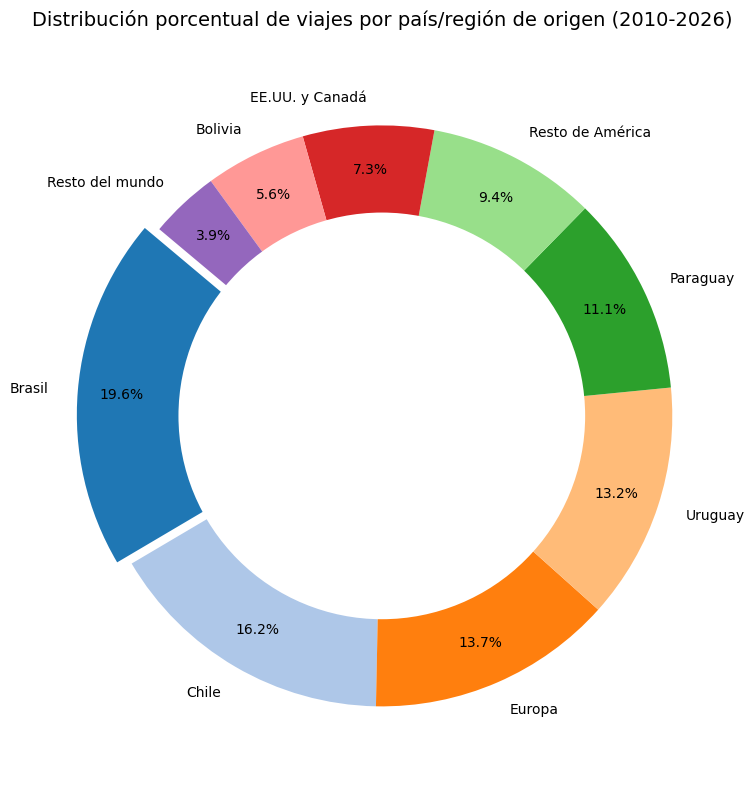

In [47]:
# CREAMOS UN GRÁFICO DE TORTA BASADO EN LA TABLA DE PAÍSES DE ORIGEN

import matplotlib.pyplot as plt

# Nos aseguramos de calcular la variable si no existe en el entorno actual
if 'visitas_por_pais' not in globals():
    visitas_por_pais = turismo.groupby('pais_origen')['viajes_de_turistas_no_residentes'].sum().sort_values(ascending=False)

# Definimos los datos a utilizar
valores = visitas_por_pais.values
etiquetas = visitas_por_pais.index

# Configuración de colores y destacar el primer elemento (Brasil)
colores = ['#1f77b4', '#aec7e8', '#ff7f0e', '#ffbb78', '#2ca02c', '#98df8a', '#d62728', '#ff9896', '#9467bd']
explode = [0.05 if i == 0 else 0 for i in range(len(valores))]

plt.figure(figsize=(10, 8))

# Crear el gráfico de torta
plt.pie(
    valores,
    labels=etiquetas,
    autopct='%1.1f%%',
    startangle=140,
    colors=colores,
    explode=explode,
    pctdistance=0.85,
    textprops={'fontsize': 10}
)

# Dibujar un círculo blanco en el centro para transformarlo en un gráfico de dona (mejora la legibilidad)
centro_circulo = plt.Circle((0,0), 0.70, fc='white')
fig = plt.gcf()
fig.gca().add_artist(centro_circulo)

plt.title("Distribución porcentual de viajes por país/región de origen (2010-2026)", fontsize=14, pad=20)
plt.tight_layout()
plt.show()

Se observa que Brasil ocupa el primer lugar, seguido por Chile, Europa, Uruguay y Paraguay.

Estos resultados muestran la importancia de los países limítrofes como mercados emisores de turismo hacia Argentina.

El análisis permite concluir que existe una participación destacada de los países vecinos en el turismo receptivo argentino.

---
### **En el análisis anterior, se observa una caída muy marcada y una posterior recuperación entre el periodo 2019 y 2023 en el marco de la Pandemia COVID-19 que nos lleva a profundizar nuestro análisis:**

Calculamos cuánto disminuyó el turismo entre 2019 y 2023:

In [48]:
# Primero definimos 'viajes_pandemia' a partir de 'visitas_por_anio' para el rango 2019-2023
# Filtramos los años de interés y establecemos el Año como índice
viajes_pandemia = visitas_por_anio[
    (visitas_por_anio['Año'] >= 2019) & (visitas_por_anio['Año'] <= 2023)
].set_index('Año')['Cantidad de visitas']

# Tomar 2019 como referencia
viajes_2019 = viajes_pandemia.loc[2019]

# Calcular variación respecto a 2019
variacion = (
    (viajes_pandemia / viajes_2019) - 1
) * 100

print("Variación respecto a 2019:")
variacion.round(2).map("{:+.2f}%".format)

Variación respecto a 2019:


,Cantidad de visitas
Año,
2019,+0.00%
2020,-71.76%
2021,-95.98%
2022,-47.43%
2023,-1.53%


### **Impacto de la pandemia en el turismo no residente en Argentina**

El análisis de los viajes de turistas no residentes entre 2019 y 2023 evidencia una fuerte disminución durante los años de la pandemia de COVID-19.

En 2019 se registraron aproximadamente 7,4 millones de viajes, mientras que en 2020 esta cifra descendió a 2,1 millones. La caída se profundizó en 2021, cuando se alcanzó un mínimo de aproximadamente 297 mil viajes, equivalente a una disminución del 96% respecto de 2019.

Durante 2022 se observó una recuperación significativa, con aproximadamente 3,9 millones de viajes registrados. Sin embargo, esta cifra todavía se encontraba un 47,4% por debajo del nivel previo a la pandemia.

En 2023, los viajes alcanzaron aproximadamente 7,3 millones, acercándose a los valores de 2019.

Estos resultados muestran una fuerte ruptura en la evolución del turismo receptivo argentino durante la pandemia y una recuperación progresiva en los años posteriores. Aunque la caída coincide temporalmente con las restricciones a la movilidad internacional, los datos analizados por sí solos no permiten determinar cuánto de esa disminución fue causado por cada factor.

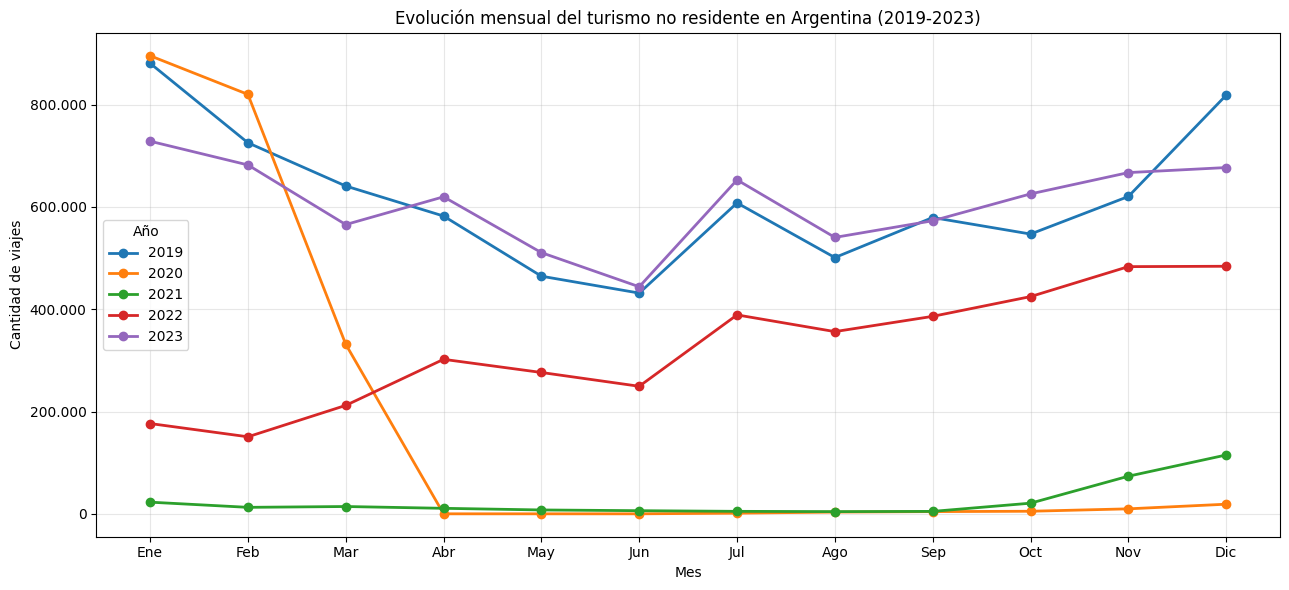

In [49]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# Como 'indice_tiempo' ya es datetime, creamos/aseguramos las columnas de año y mes de forma directa
turismo["anio"] = turismo["indice_tiempo"].dt.year
turismo["mes"] = turismo["indice_tiempo"].dt.month

# Filtrar los años de interés
datos = turismo[turismo["anio"].between(2019, 2023)]

# Agrupar viajes por mes y año
comparacion = (
    datos.groupby(["mes", "anio"])[
        "viajes_de_turistas_no_residentes"
    ]
    .sum()
    .unstack()
)

# Crear gráfico
plt.figure(figsize=(13, 6))

for anio in comparacion.columns:
    plt.plot(
        comparacion.index,
        comparacion[anio],
        marker="o",
        linewidth=2,
        label=str(anio)
    )

plt.title(
    "Evolución mensual del turismo no residente "
    "en Argentina (2019-2023)"
)

plt.xlabel("Mes")
plt.ylabel("Cantidad de viajes")

plt.xticks(
    range(1, 13),
    ["Ene", "Feb", "Mar", "Abr", "May", "Jun",
     "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]
)

plt.gca().yaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"{x:,.0f}".replace(",", "."))
)

plt.legend(title="Año")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("lineas_superpuestas_pandemia.png", dpi=300)
plt.show()

Cada línea representa un año diferente, y cada punto muestra los viajes registrados durante un mes.

De esta manera, podemos comparar cómo se comportó el turismo en un mismo mes durante distintos años.

### Relación entre el mes del año y la cantidad de viajes turísticos

El gráfico de líneas superpuestas permite analizar la relación entre el mes del año y la cantidad de viajes de turistas no residentes a Argentina, comparando el comportamiento de esta variable entre 2019 y 2023.

La utilización de líneas diferenciadas por año permite identificar cambios en la evolución mensual del turismo durante la pandemia y su posterior recuperación.

La comparación con 2019, considerado como período de referencia previo a la pandemia, permite evaluar la magnitud de la disminución registrada en 2020 y 2021, así como el grado de recuperación observado durante 2022 y 2023.

Además, el análisis permite investigar la existencia de patrones estacionales y determinar si el comportamiento mensual del turismo recuperó características similares a las observadas antes de la pandemia.